In [3]:
   !pip -q install ucimlrepo statsmodels

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm

sns.set_theme(style="whitegrid")

# Option A: download straight from UCI (needs internet + ucimlrepo installed)
# Option B: if you downloaded the CSV, put it next to this notebook and it
#           will be used automatically.
CSV_PATH = "online_shoppers_intention.csv"

try:
    df = pd.read_csv(CSV_PATH)
    print("Loaded from CSV")
except FileNotFoundError:
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=468)
    df = pd.concat([ds.data.features, ds.data.targets], axis=1)
    print("Loaded from UCI")

print(df.shape)          # rows, columns
print(df.head())

Loaded from UCI
(12330, 18)
   Administrative  Administrative_Duration  Informational  \
0               0                      0.0              0   
1               0                      0.0              0   
2               0                      0.0              0   
3               0                      0.0              0   
4               0                      0.0              0   

   Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                     0.0               1                 0.000000   
1                     0.0               2                64.000000   
2                     0.0               1                 0.000000   
3                     0.0               2                 2.666667   
4                     0.0              10               627.500000   

   BounceRates  ExitRates  PageValues  SpecialDay Month  OperatingSystems  \
0         0.20       0.20         0.0         0.0   Feb                 1   
1         0.00       0.10     

In [5]:
print(df.dtypes)
print("Missing values per column:\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

# Make the two True/False columns into 0/1 numbers so we can calculate with them.
df["Revenue"] = df["Revenue"].astype(int)   # 1 = session ended in a purchase
df["Weekend"] = df["Weekend"].astype(int)

# Time columns are in seconds -> convert to minutes (easier to read).
for col in ["Administrative_Duration", "Informational_Duration",
            "ProductRelated_Duration"]:
    df[col + "_min"] = df[col] / 60

print("Overall purchase rate:", round(df["Revenue"].mean() * 100, 1), "%")
print(df["VisitorType"].value_counts())

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
Revenue                       bool
dtype: object
Missing values per column:
 Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
Operating

In [6]:
num_cols = ["Administrative_Duration_min", "Informational_Duration_min",
            "ProductRelated_Duration_min", "BounceRates", "ExitRates", "PageValues"]
print(df[num_cols].describe().round(3))

print("\nPurchase rate by visitor type (%):")
print((df.groupby("VisitorType")["Revenue"].mean() * 100).round(1))

print("\nMedian product-page time (min) by purchase outcome:")
print(df.groupby("Revenue")["ProductRelated_Duration_min"].median().round(2))

       Administrative_Duration_min  Informational_Duration_min  \
count                    12330.000                   12330.000   
mean                         1.347                       0.575   
std                          2.946                       2.346   
min                          0.000                       0.000   
25%                          0.000                       0.000   
50%                          0.125                       0.000   
75%                          1.554                       0.000   
max                         56.646                      42.490   

       ProductRelated_Duration_min  BounceRates  ExitRates  PageValues  
count                    12330.000    12330.000  12330.000   12330.000  
mean                        19.912        0.022      0.043       5.889  
std                         31.894        0.048      0.049      18.568  
min                          0.000        0.000      0.000       0.000  
25%                          3.069      

In [7]:
h1 = df[df["VisitorType"].isin(["New_Visitor", "Returning_Visitor"])]
# "Other" is a tiny group, so we leave it out for this test. Say so in README.

table = pd.crosstab(h1["VisitorType"], h1["Revenue"])
print(table)

chi2, p, dof, expected = stats.chi2_contingency(table)
n = table.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))   # effect size
print(f"chi2 = {chi2:.2f}, df = {dof}, p = {p:.4g}, Cramer's V = {cramers_v:.3f}")

Revenue               0     1
VisitorType                  
New_Visitor        1272   422
Returning_Visitor  9081  1470
chi2 = 133.84, df = 1, p = 5.91e-31, Cramer's V = 0.105


In [8]:
buy = df.loc[df["Revenue"] == 1, "ProductRelated_Duration_min"]
no_buy = df.loc[df["Revenue"] == 0, "ProductRelated_Duration_min"]

u, p = stats.mannwhitneyu(buy, no_buy, alternative="two-sided")
rank_biserial = 2 * u / (len(buy) * len(no_buy)) - 1       # effect size
print(f"Median (buy) = {buy.median():.2f} min, median (no buy) = {no_buy.median():.2f} min")
print(f"U = {u:.0f}, p = {p:.4g}, rank-biserial r = {rank_biserial:.3f}")

Median (buy) = 18.50 min, median (no buy) = 8.50 min
U = 13382713, p = 5.332e-128, rank-biserial r = 0.346


In [9]:
print("Correlation between BounceRates and ExitRates:",
      round(df["BounceRates"].corr(df["ExitRates"]), 2))
# These two are usually very highly correlated, so we do NOT put both in one
# model. We run two models and compare. Mention this in your limitations.

d = df.copy()
d["ExitRate_pct"] = d["ExitRates"] * 100          # per 1 percentage point
d["BounceRate_pct"] = d["BounceRates"] * 100
d["NewVisitor"] = (d["VisitorType"] == "New_Visitor").astype(int)

def fit_logit(rate_col):
    X = d[[rate_col, "ProductRelated_Duration_min", "NewVisitor", "Weekend"]]
    X = sm.add_constant(X)
    model = sm.Logit(d["Revenue"], X).fit(disp=False)
    out = pd.DataFrame({
        "odds_ratio": np.exp(model.params),
        "ci_low": np.exp(model.conf_int()[0]),
        "ci_high": np.exp(model.conf_int()[1]),
        "p_value": model.pvalues,
    }).round(4)
    print(f"\nModel with {rate_col}:  (n = {int(model.nobs)})")
    print(out)
    return out

or_exit = fit_logit("ExitRate_pct")
or_bounce = fit_logit("BounceRate_pct")

Correlation between BounceRates and ExitRates: 0.91

Model with ExitRate_pct:  (n = 12330)
                             odds_ratio  ci_low  ci_high  p_value
const                            0.3371  0.3013   0.3772    0.000
ExitRate_pct                     0.7328  0.7094   0.7570    0.000
ProductRelated_Duration_min      1.0072  1.0058   1.0087    0.000
NewVisitor                       1.4672  1.2846   1.6758    0.000
Weekend                          1.0804  0.9617   1.2137    0.193

Model with BounceRate_pct:  (n = 12330)
                             odds_ratio  ci_low  ci_high  p_value
const                            0.1687  0.1553   0.1833   0.0000
BounceRate_pct                   0.7518  0.7173   0.7878   0.0000
ProductRelated_Duration_min      1.0101  1.0087   1.0116   0.0000
NewVisitor                       1.8163  1.5951   2.0681   0.0000
Weekend                          1.1266  1.0041   1.2642   0.0425


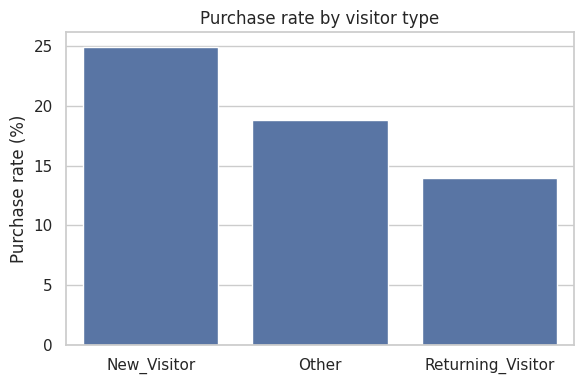

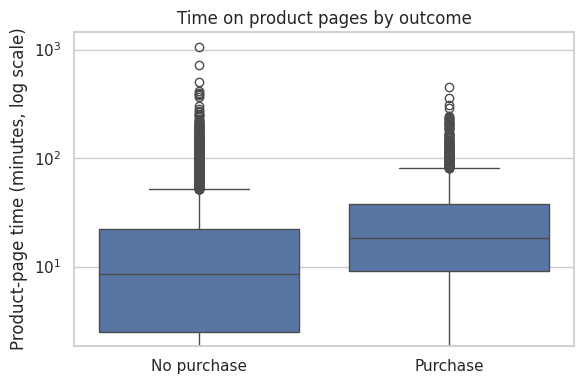

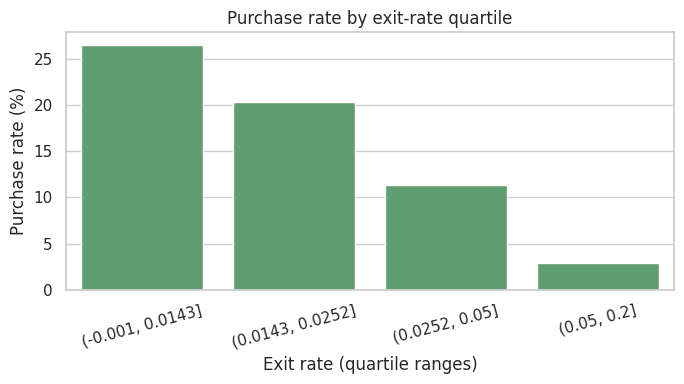

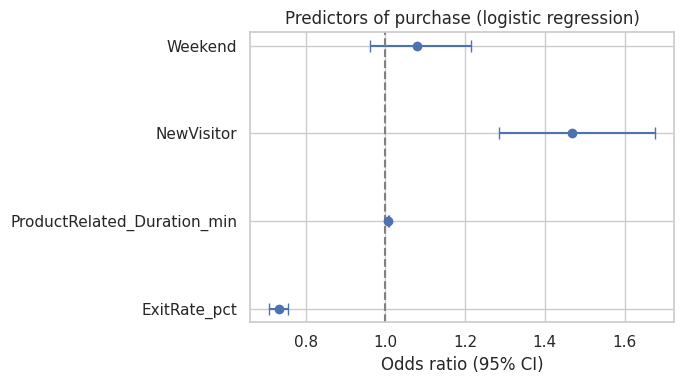

In [11]:
# Chart 1: purchase rate by visitor type
rate = (df.groupby("VisitorType")["Revenue"].mean() * 100).reset_index()
plt.figure(figsize=(6, 4))
sns.barplot(data=rate, x="VisitorType", y="Revenue", color="#4C72B0")
plt.ylabel("Purchase rate (%)")
plt.xlabel("")
plt.title("Purchase rate by visitor type")
plt.tight_layout()
plt.savefig("chart1_visitor_type.png", dpi=150)
plt.show()

# Chart 2: product-page time (log scale because the data is skewed)
plt.figure(figsize=(6, 4))
plot_df = df.assign(Outcome=df["Revenue"].map({0: "No purchase", 1: "Purchase"}))
sns.boxplot(data=plot_df, x="Outcome", y="ProductRelated_Duration_min")
plt.yscale("log")
plt.ylabel("Product-page time (minutes, log scale)")
plt.xlabel("")
plt.title("Time on product pages by outcome")
plt.tight_layout()
plt.savefig("chart2_product_time.png", dpi=150)
plt.show()

# Chart 3: purchase rate across exit-rate quartiles
df["ExitQuartile"] = pd.qcut(df["ExitRates"], 4, duplicates="drop")
q = (df.groupby("ExitQuartile", observed=True)["Revenue"].mean() * 100).reset_index()
q["ExitQuartile"] = q["ExitQuartile"].astype(str)
plt.figure(figsize=(7, 4))
sns.barplot(data=q, x="ExitQuartile", y="Revenue", color="#55A868")
plt.ylabel("Purchase rate (%)")
plt.xlabel("Exit rate (quartile ranges)")
plt.title("Purchase rate by exit-rate quartile")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("chart3_exit_quartiles.png", dpi=150)
plt.show()

# Chart 4: odds ratios (Exit-rate model) with confidence intervals
plot_or = or_exit.drop(index="const")
plt.figure(figsize=(7, 4))
plt.errorbar(plot_or["odds_ratio"], range(len(plot_or)),
             xerr=[plot_or["odds_ratio"] - plot_or["ci_low"],
                   plot_or["ci_high" ] - plot_or["odds_ratio"]],
             fmt="o", capsize=4)
plt.axvline(1, linestyle="--", color="grey")
plt.yticks(range(len(plot_or)), plot_or.index)
plt.xlabel("Odds ratio (95% CI)")
plt.title("Predictors of purchase (logistic regression)")
plt.tight_layout()
plt.savefig("chart4_odds_ratios.png", dpi=150)
plt.show()